# Projet RNN — Drug Review : notebook corrigé
**Mode d'emploi :** importe ce notebook dans Colab, sélectionne le GPU T4, puis clique sur **Tout exécuter**. Autorise Google Drive dans la première cellule.

Les cellules sont maintenant dans l'ordre : configuration → téléchargement → préparation → vocabulaire → lots → modèles → entraînements → comparaison → sauvegarde.

- Les trois modèles sont entraînés pendant 5 époques, avec sélection par macro-F1 de validation.
- Les fichiers sont enregistrés dans `MyDrive/Projet_RNN_Drug_Review/corrected_v2`.
- Après une déconnexion, relance **Tout exécuter** : un entraînement terminé est rechargé, un entraînement interrompu reprend après sa dernière époque sauvegardée. Une époque interrompue en cours sera recommencée.
- Les anciennes sauvegardes du dossier parent sont conservées. Cette version utilise un dossier distinct car le protocole de mélange des lots est désormais identique pour les trois architectures.
- Les expériences supplémentaires et le test final sont désactivés par défaut. Nous les lancerons après vérification des trois premiers résultats.

La référence historique observée avant la réinitialisation était : Vanilla 0,592641 ; CIFG 0,590749 ; WMC 0,585633 en macro-F1 de validation. Ce sont des résultats antérieurs, pas des sorties de ce notebook corrigé. Les poids perdus ne peuvent pas être recréés à partir de ces scores.


## 1. Configuration et sauvegarde Google Drive


In [18]:
from google.colab import drive
from pathlib import Path
import os, json, random, hashlib, io, zipfile, urllib.request, time
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from IPython.display import display
from tqdm.auto import tqdm
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

# Cette cellule doit rester la première cellule de code.
drive.mount('/content/drive')
PROJECT_DIR = Path('/content/drive/MyDrive/Projet_RNN_Drug_Review')
WORK_DIR = PROJECT_DIR / 'corrected_v2'
WORK_DIR.mkdir(parents=True, exist_ok=True)
# Ne pas changer de répertoire : tous les chemins de sauvegarde sont explicites.
SEED = 42
MAX_VOCAB = 20000
MAX_LEN = 128
EPOCHS = 5
BATCH_SIZE = 64
RUN_HYPERPARAMETERS = True
RUN_FINAL_TEST = True

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed(SEED)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Sauvegardes :', WORK_DIR)
print('PyTorch :', torch.__version__, '| Appareil :', device)
if device.type == 'cuda':
    print('GPU :', torch.cuda.get_device_name(0))
else:
    print('CPU actif : active le GPU T4 avant les entraînements pour gagner du temps.')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Sauvegardes : /content/drive/MyDrive/Projet_RNN_Drug_Review/corrected_v2
PyTorch : 2.11.0+cpu | Appareil : cpu
CPU actif : active le GPU T4 avant les entraînements pour gagner du temps.


## 2. Télécharger les données — lien corrigé et copie en cache


In [19]:
archive_path = WORK_DIR / 'drugsCom_raw.zip'
url = 'https://archive.ics.uci.edu/ml/machine-learning-databases/00462/drugsCom_raw.zip'
if not archive_path.exists():
    print('Téléchargement du dataset UCI...')
    temporary = archive_path.with_suffix('.download')
    with urllib.request.urlopen(url, timeout=120) as response:
        content = response.read()
    with zipfile.ZipFile(io.BytesIO(content)) as archive:
        assert archive.testzip() is None, 'Archive endommagée.'
    temporary.write_bytes(content)
    os.replace(temporary, archive_path)
else:
    print('Dataset trouvé dans Google Drive : pas de nouveau téléchargement.')

with zipfile.ZipFile(archive_path) as archive:
    train_file = next(n for n in archive.namelist() if n.endswith('drugsComTrain_raw.tsv'))
    test_file = next(n for n in archive.namelist() if n.endswith('drugsComTest_raw.tsv'))
    with archive.open(train_file) as stream:
        train_df = pd.read_csv(stream, sep='\t')
    with archive.open(test_file) as stream:
        test_df = pd.read_csv(stream, sep='\t')
print('Avis bruts :', len(train_df), 'pour le train ;', len(test_df), 'pour le test')
display(train_df[['review', 'rating']].head())


Dataset trouvé dans Google Drive : pas de nouveau téléchargement.
Avis bruts : 161297 pour le train ; 53766 pour le test


,review,rating
0,"""It has no side effect, I take it in combinati...",9.0
1,"""My son is halfway through his fourth week of ...",8.0
2,"""I used to take another oral contraceptive, wh...",5.0
3,"""This is my first time using any form of birth...",8.0
4,"""Suboxone has completely turned my life around...",9.0


## 3. Nettoyer et séparer les données
Choix du projet : notes 1–4 → négatif (0), 5–6 → neutre (1), 7–10 → positif (2).
Le protocole initial est conservé : normalisation HTML/minuscules/espaces, conservation du premier exemplaire d'un texte dupliqué, retrait du train des textes présents dans le test, puis validation stratifiée de 20 %.
Limites à discuter dans le rapport : un texte peut avoir plusieurs notes ; conserver sa première occurrence est un choix simplificateur. La suppression des doublons exacts ne supprime pas les quasi-doublons.


In [20]:
import html
import re
from sklearn.model_selection import train_test_split

SEED = 42

# Nettoyer les textes sans supprimer la ponctuation
def clean_text(text):
    text = html.unescape(str(text))
    text = text.lower().strip()
    return re.sub(r"\s+", " ", text)

# Préparer une copie des données
def prepare_data(df):
    data = df[["review", "rating"]].dropna().copy()
    data = data[data["rating"].between(1, 10)].copy()

    data["text"] = data["review"].apply(clean_text)
    data = data[data["text"].str.len() > 0].copy()

    data["label"] = data["rating"].apply(
        lambda rating: 0 if rating <= 4 else (
            1 if rating <= 6 else 2
        )
    )

    return data.drop_duplicates(subset="text").reset_index(drop=True)

train_clean = prepare_data(train_df)
test_data = prepare_data(test_df)

# Éviter qu'un même texte soit dans l'entraînement et le test
train_clean = train_clean[
    ~train_clean["text"].isin(test_data["text"])
].copy()

# Réserver 20 % pour la validation en conservant
# approximativement les proportions des catégories
train_data, val_data = train_test_split(
    train_clean,
    test_size=0.20,
    random_state=SEED,
    stratify=train_clean["label"]
)

train_data = train_data.reset_index(drop=True)
val_data = val_data.reset_index(drop=True)

# Vérifier que les ensembles ne partagent aucun texte
assert set(train_data["text"]).isdisjoint(val_data["text"])
assert set(train_data["text"]).isdisjoint(test_data["text"])
assert set(val_data["text"]).isdisjoint(test_data["text"])

print("Entraînement :", len(train_data))
print("Validation   :", len(val_data))
print("Test         :", len(test_data))

print("\nRépartition des catégories dans l'entraînement :")
print(
    train_data["label"]
    .value_counts()
    .sort_index()
    .rename(index={0: "Négatif", 1: "Neutre", 2: "Positif"})
)
for split_name, data in [('train', train_data), ('validation', val_data), ('test', test_data)]:
    data[['text', 'label']].to_csv(WORK_DIR / f'{split_name}_data.csv', index=False)


Entraînement : 64140
Validation   : 16036
Test         : 48266

Répartition des catégories dans l'entraînement :
label
Négatif    15781
Neutre      5678
Positif    42681
Name: count, dtype: int64


## 4. Vocabulaire appris uniquement sur le train


In [21]:
from collections import Counter

# Réglages de départ
MAX_VOCAB = 20000
MAX_LEN = 128

# Découper un texte en mots et signes de ponctuation
def tokenize(text):
    return re.findall(r"\w+(?:'\w+)*|[^\w\s]", text)

# Compter les mots uniquement dans l'entraînement
word_counts = Counter()

for text in train_data["text"]:
    word_counts.update(tokenize(text))

# Deux codes spéciaux :
# 0 = remplissage des séquences courtes
# 1 = mot absent du vocabulaire
vocab = {"<PAD>": 0, "<UNK>": 1}

for word, count in word_counts.most_common(MAX_VOCAB - 2):
    vocab[word] = len(vocab)

# Convertir un texte en une séquence de nombres
def encode(text):
    tokens = tokenize(text)[:MAX_LEN]
    ids = [vocab.get(token, 1) for token in tokens]
    return ids if ids else [1]

# Appliquer le même vocabulaire aux trois ensembles
for data in (train_data, val_data, test_data):
    data["input_ids"] = data["text"].apply(encode)

print("Taille du vocabulaire :", len(vocab))
print("Longueur maximale :", MAX_LEN, "tokens")

print("\nExemple de texte :")
print(train_data.iloc[0]["text"][:250])

print("\nLes 20 premiers codes :")
print(train_data.iloc[0]["input_ids"][:20])

# Mesurer combien de textes d'entraînement seront raccourcis
lengths = train_data["text"].apply(lambda text: len(tokenize(text)))
print(
    "\nAvis d'entraînement dépassant la longueur maximale :",
    f"{(lengths > MAX_LEN).mean():.1%}"
)
with open(WORK_DIR / 'vocab.json', 'w', encoding='utf-8') as stream:
    json.dump(vocab, stream, ensure_ascii=False)
# Empreinte des données ordonnées et du vocabulaire pour sécuriser la reprise.
digest = hashlib.sha256()
for split_name, data in [('train', train_data), ('validation', val_data), ('test', test_data)]:
    digest.update(split_name.encode())
    for text, label in zip(data['text'], data['label']):
        digest.update(json.dumps([text, int(label)], ensure_ascii=False).encode())
        digest.update(b'\n')
digest.update(json.dumps(vocab, sort_keys=True).encode())
DATA_FINGERPRINT = digest.hexdigest()


Taille du vocabulaire : 20000
Longueur maximale : 128 tokens

Exemple de texte :
"it's maybe my 5th week on the drug, noticed an increase in my productivity and feel like i can get a lot done. although i'm suffering from nausea and slight headaches, i'm taking other medications so it's hard to say. tried ritalin, ritalin xr and d

Les 20 premiers codes :
[7, 79, 409, 10, 1537, 85, 17, 6, 136, 5, 250, 89, 528, 18, 10, 7519, 4, 69, 55, 3]

Avis d'entraînement dépassant la longueur maximale : 33.4%


## 5. Exploration des données pour le rapport et les slides


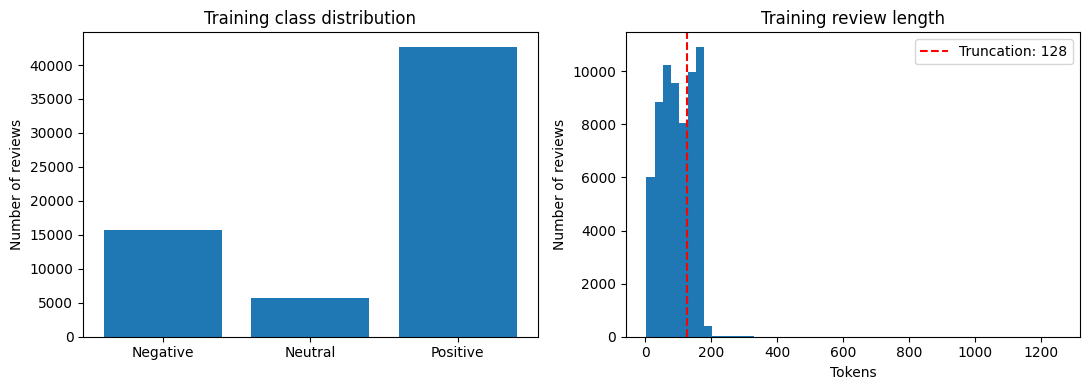

Accuracy de référence si on prédit toujours la classe majoritaire : 66.54%


In [22]:
import matplotlib.pyplot as plt
class_counts = train_data['label'].value_counts().reindex([0, 1, 2], fill_value=0)
full_lengths = train_data['text'].apply(lambda text: len(tokenize(text)))
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].bar(['Negative', 'Neutral', 'Positive'], class_counts.values)
axes[0].set(title='Training class distribution', ylabel='Number of reviews')
axes[1].hist(full_lengths, bins=50)
axes[1].axvline(MAX_LEN, color='red', linestyle='--', label=f'Truncation: {MAX_LEN}')
axes[1].set(title='Training review length', xlabel='Tokens', ylabel='Number of reviews')
axes[1].legend()
fig.tight_layout()
fig.savefig(WORK_DIR / 'eda.png', dpi=180)
plt.show()
print('Accuracy de référence si on prédit toujours la classe majoritaire :', f'{class_counts.max()/class_counts.sum():.2%}')


## 6. Lots PyTorch et poids des catégories


In [23]:
import random
import numpy as np
import torch
from torch.utils.data import Dataset, DataLoader
from torch.nn.utils.rnn import pad_sequence

# Fixer les graines aléatoires
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

BATCH_SIZE = 64

# Associer chaque séquence à sa catégorie
class ReviewDataset(Dataset):
    def __init__(self, dataframe):
        self.sequences = [
            torch.tensor(ids, dtype=torch.long)
            for ids in dataframe["input_ids"]
        ]
        self.labels = dataframe["label"].tolist()

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, index):
        return self.sequences[index], self.labels[index]

# Compléter les séquences courtes avec des zéros
def collate_batch(batch):
    sequences, labels = zip(*batch)

    lengths = torch.tensor(
        [len(sequence) for sequence in sequences],
        dtype=torch.long
    )

    inputs = pad_sequence(
        sequences,
        batch_first=True,
        padding_value=0
    )

    labels = torch.tensor(labels, dtype=torch.long)

    return inputs, lengths, labels

train_dataset = ReviewDataset(train_data)
val_dataset = ReviewDataset(val_data)
test_dataset = ReviewDataset(test_data)


def make_train_loader(batch_size=64, seed=SEED):
    return DataLoader(
        train_dataset, batch_size=batch_size, shuffle=True,
        collate_fn=collate_batch,
        generator=torch.Generator().manual_seed(seed)
    )

val_loader = DataLoader(val_dataset, batch_size=64, shuffle=False, collate_fn=collate_batch)
test_loader = DataLoader(test_dataset, batch_size=64, shuffle=False, collate_fn=collate_batch)
train_loader = make_train_loader()
# Vérifier sur la validation pour ne pas consommer le générateur du train.
inputs, lengths, labels = next(iter(val_loader))
print('Dimensions :', inputs.shape, lengths.shape, labels.shape)
print('Nombre de lots train :', len(train_loader))
counts = train_data['label'].value_counts().reindex([0, 1, 2]).to_numpy()
assert np.all(counts > 0), 'Une catégorie est absente du train.'
class_weights = torch.tensor(len(train_data)/(3*counts), dtype=torch.float32, device=device)
criterion = nn.CrossEntropyLoss(weight=class_weights, reduction='sum')


Dimensions : torch.Size([64, 128]) torch.Size([64]) torch.Size([64])
Nombre de lots train : 1003


## 7. Cellules Vanilla, CIFG et WMC — sans `nn.LSTM` ni `nn.LSTMCell`


In [24]:
import torch.nn as nn

# Cellule LSTM classique
class VanillaLSTMCell(nn.Module):
    def __init__(self, input_size, hidden_size):
        super().__init__()

        # Calcul groupé des quatre portes
        self.x_linear = nn.Linear(input_size, 4 * hidden_size)
        self.h_linear = nn.Linear(
            hidden_size, 4 * hidden_size, bias=False
        )

    def forward(self, x, h, c):
        gates = self.x_linear(x) + self.h_linear(h)
        i, f, o, g = gates.chunk(4, dim=-1)

        i = torch.sigmoid(i)  # Porte d'entrée
        f = torch.sigmoid(f)  # Porte d'oubli
        o = torch.sigmoid(o)  # Porte de sortie
        g = torch.tanh(g)     # Nouvelle information candidate

        c_new = f * c + i * g
        h_new = o * torch.tanh(c_new)

        return h_new, c_new


# Modèle de classification
class LSTMClassifier(nn.Module):
    def __init__(
        self,
        vocab_size,
        embedding_dim=128,
        hidden_size=128,
        num_classes=3,
        dropout=0.3
    ):
        super().__init__()

        self.hidden_size = hidden_size

        self.embedding = nn.Embedding(
            vocab_size, embedding_dim, padding_idx=0
        )
        self.cell = VanillaLSTMCell(embedding_dim, hidden_size)
        self.dropout = nn.Dropout(dropout)
        self.classifier = nn.Linear(hidden_size, num_classes)

    def forward(self, inputs, lengths):
        embedded = self.embedding(inputs)
        batch_size, sequence_length, _ = embedded.shape

        h = embedded.new_zeros(batch_size, self.hidden_size)
        c = embedded.new_zeros(batch_size, self.hidden_size)

        lengths = lengths.to(inputs.device)

        for t in range(sequence_length):
            h_new, c_new = self.cell(embedded[:, t, :], h, c)

            # Conserver la mémoire quand le texte est terminé :
            # les zéros de remplissage ne modifient pas l'état.
            active = (t < lengths).unsqueeze(1)
            h = torch.where(active, h_new, h)
            c = torch.where(active, c_new, c)

        # Trois scores par avis, sans softmax avant CrossEntropyLoss
        return self.classifier(self.dropout(h))



# 1. Variante CIFG :
# la porte d'entrée est égale à 1 - porte d'oubli
class CIFGLSTMCell(nn.Module):
    def __init__(self, input_size, hidden_size):
        super().__init__()

        self.x_linear = nn.Linear(input_size, 3 * hidden_size)
        self.h_linear = nn.Linear(
            hidden_size, 3 * hidden_size, bias=False
        )

    def forward(self, x, h, c):
        gates = self.x_linear(x) + self.h_linear(h)
        f, o, g = gates.chunk(3, dim=-1)

        f = torch.sigmoid(f)
        i = 1 - f
        o = torch.sigmoid(o)
        g = torch.tanh(g)

        c_new = f * c + i * g
        h_new = o * torch.tanh(c_new)

        return h_new, c_new


# 2. Variante WMC :
# la mémoire intervient dans le calcul des portes
class WMCLSTMCell(nn.Module):
    def __init__(self, input_size, hidden_size):
        super().__init__()

        self.x_linear = nn.Linear(input_size, 4 * hidden_size)
        self.h_linear = nn.Linear(
            hidden_size, 4 * hidden_size, bias=False
        )

        self.c_i = nn.Linear(hidden_size, hidden_size, bias=False)
        self.c_f = nn.Linear(hidden_size, hidden_size, bias=False)
        self.c_o = nn.Linear(hidden_size, hidden_size, bias=False)

    def forward(self, x, h, c):
        gates = self.x_linear(x) + self.h_linear(h)
        i_raw, f_raw, o_raw, g_raw = gates.chunk(4, dim=-1)

        i = torch.sigmoid(i_raw + torch.tanh(self.c_i(c)))
        f = torch.sigmoid(f_raw + torch.tanh(self.c_f(c)))
        g = torch.tanh(g_raw)

        c_new = f * c + i * g

        # La porte de sortie utilise la nouvelle mémoire
        o = torch.sigmoid(o_raw + torch.tanh(self.c_o(c_new)))
        h_new = o * torch.tanh(c_new)

        return h_new, c_new


# Réutiliser le même classifieur en changeant la cellule
class VariantClassifier(LSTMClassifier):
    def __init__(
        self,
        vocab_size,
        cell_class,
        embedding_dim=128,
        hidden_size=128,
        num_classes=3,
        dropout=0.3
    ):
        super().__init__(
            vocab_size=vocab_size,
            embedding_dim=embedding_dim,
            hidden_size=hidden_size,
            num_classes=num_classes,
            dropout=dropout
        )

        self.cell = cell_class(embedding_dim, hidden_size)



def build_model(architecture, embedding_dim=128, hidden_size=128, dropout=0.3):
    arguments = dict(vocab_size=len(vocab), embedding_dim=embedding_dim,
                     hidden_size=hidden_size, num_classes=3, dropout=dropout)
    if architecture == 'Vanilla':
        return LSTMClassifier(**arguments).to(device)
    cells = {'CIFG': CIFGLSTMCell, 'WMC': WMCLSTMCell}
    return VariantClassifier(cell_class=cells[architecture], **arguments).to(device)


## 8. Vérifier les sorties, les gradients et le traitement du remplissage


In [25]:
for architecture in ['Vanilla', 'CIFG', 'WMC']:
    set_seed(SEED)
    candidate = build_model(architecture)
    candidate.eval()
    x = torch.tensor([[2, 3, 4], [3, 4, 0]], device=device)
    lens = torch.tensor([3, 2], device=device)
    with torch.no_grad():
        scores = candidate(x, lens)
        padded_scores = candidate(torch.nn.functional.pad(x, (0, 3)), lens)
    assert scores.shape == (2, 3)
    assert torch.isfinite(scores).all()
    assert torch.allclose(scores, padded_scores, atol=1e-6), 'Le padding modifie les scores.'
    candidate.train()
    candidate(x, lens).square().mean().backward()
    assert all(p.grad is not None and torch.isfinite(p.grad).all()
               for p in candidate.parameters() if p.requires_grad)
    print(architecture, ': vérifications réussies ; paramètres =',
          sum(p.numel() for p in candidate.parameters() if p.requires_grad))
    del candidate


Vanilla : vérifications réussies ; paramètres = 2691971
CIFG : vérifications réussies ; paramètres = 2659075
WMC : vérifications réussies ; paramètres = 2741123


## 9. Entraînement commun et reprise automatique
Même architecture de classification, mêmes partitions, même vocabulaire, même perte, même budget de 5 époques. Chaque expérience repart de la graine 42 et d'un nouveau chargeur de train.

Le checkpoint contient l'état de la dernière époque, celui de l'optimiseur, les états aléatoires, l'historique et les meilleurs poids. Les scores du rapport doivent provenir des nouvelles sorties réellement calculées. La reproductibilité exacte n'est pas garantie entre différents matériels ou versions de PyTorch.


In [30]:
def run_epoch(model, loader, optimizer=None):
    training = optimizer is not None
    model.train(training)

    loss_sum = 0.0
    weight_sum = 0.0
    true_labels = []
    predictions = []

    with torch.set_grad_enabled(training):
        for inputs, lengths, labels in tqdm(
            loader,
            desc="Entraînement" if training else "Évaluation",
            leave=False
        ):
            inputs = inputs.to(device)
            lengths = lengths.to(device)
            labels = labels.to(device)

            if training:
                optimizer.zero_grad(set_to_none=True)

            logits = model(inputs, lengths)

            batch_loss_sum = criterion(logits, labels)
            batch_weight_sum = class_weights[labels].sum()
            loss = batch_loss_sum / batch_weight_sum

            if not torch.isfinite(loss):
                raise RuntimeError("Perte non finie.")

            if training:
                loss.backward()
                nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                optimizer.step()

            loss_sum += batch_loss_sum.item()
            weight_sum += batch_weight_sum.item()

            true_labels.extend(labels.detach().cpu().tolist())
            predictions.extend(
                logits.argmax(dim=1).detach().cpu().tolist()
            )

    return {
        "loss": loss_sum / weight_sum,
        "accuracy": accuracy_score(true_labels, predictions),
        "macro_f1": f1_score(
            true_labels,
            predictions,
            labels=[0, 1, 2],
            average="macro",
            zero_division=0
        )
    }


def atomic_save(payload, path):
    temporary = path.with_suffix(path.suffix + ".tmp")
    torch.save(payload, temporary)
    os.replace(temporary, path)


def cpu_state(model):
    return {
        key: value.detach().cpu().clone()
        for key, value in model.state_dict().items()
    }


def capture_rng(loader):
    ns = np.random.get_state()

    return {
        "python": random.getstate(),
        "numpy": [
            ns[0],
            ns[1].tolist(),
            int(ns[2]),
            int(ns[3]),
            float(ns[4])
        ],
        "torch": torch.get_rng_state(),
        "cuda": (
            torch.cuda.get_rng_state_all()
            if torch.cuda.is_available()
            else []
        ),
        "loader": loader.generator.get_state()
    }


def restore_rng(state, loader):
    random.setstate(state["python"])

    ns = state["numpy"]
    np.random.set_state((
        ns[0],
        np.array(ns[1], dtype=np.uint32),
        ns[2],
        ns[3],
        ns[4]
    ))

    torch.set_rng_state(state["torch"].cpu())

    if (
        torch.cuda.is_available()
        and len(state["cuda"]) == torch.cuda.device_count()
    ):
        torch.cuda.set_rng_state_all([
            value.cpu() for value in state["cuda"]
        ])

    loader.generator.set_state(state["loader"].cpu())


def fit_experiment(
    name,
    architecture,
    lr=0.001,
    optimizer_name="Adam",
    batch_size=64
):
    config = dict(
        protocol="corrected_v2",
        architecture=architecture,
        lr=lr,
        optimizer=optimizer_name,
        batch_size=batch_size,
        seed=SEED,
        epochs=EPOCHS,
        embedding_dim=128,
        hidden_size=128,
        dropout=0.3,
        max_len=MAX_LEN,
        data_fingerprint=DATA_FINGERPRINT,
        class_weights=class_weights.detach().cpu().tolist(),
        pytorch_version=str(torch.__version__)
    )

    run_dir = WORK_DIR / name
    run_dir.mkdir(parents=True, exist_ok=True)
    checkpoint_path = run_dir / "checkpoint.pt"

    set_seed(SEED)
    trained_model = build_model(architecture)
    loader = make_train_loader(batch_size)

    optimizer_class = {
        "Adam": torch.optim.Adam,
        "RMSprop": torch.optim.RMSprop
    }[optimizer_name]

    experiment_optimizer = optimizer_class(
        trained_model.parameters(),
        lr=lr
    )

    records = []
    best_score = -1.0
    best_state = None
    start_epoch = 1

    if checkpoint_path.exists():
        saved = torch.load(
            checkpoint_path,
            map_location="cpu",
            weights_only=True
        )

        # Accepter les variantes CPU/GPU de la même version.
        config_sauvee = dict(saved["config"])
        config_actuelle = dict(config)

        for configuration in (config_sauvee, config_actuelle):
            configuration["pytorch_version"] = (
                configuration["pytorch_version"].split("+")[0]
            )

        if config_sauvee != config_actuelle:
            differences = {
                cle: {
                    "sauvegarde": config_sauvee.get(cle),
                    "actuel": config_actuelle.get(cle)
                }
                for cle in config_sauvee.keys() | config_actuelle.keys()
                if config_sauvee.get(cle) != config_actuelle.get(cle)
            }
            raise ValueError(
                f"{name} : configuration différente : {differences}"
            )

        records = saved["history"]
        best_score = saved["best_score"]
        best_state = saved["best_state"]
        start_epoch = saved["epoch"] + 1

        trained_model.load_state_dict(saved["model_state"])
        experiment_optimizer.load_state_dict(
            saved["optimizer_state"]
        )
        restore_rng(saved["rng"], loader)

        print(
            f"{name} : "
            f"{start_epoch - 1}/{EPOCHS} époques déjà sauvegardées."
        )

    for epoch in range(start_epoch, EPOCHS + 1):
        started = time.time()

        train_metrics = run_epoch(
            trained_model,
            loader,
            experiment_optimizer
        )
        val_metrics = run_epoch(trained_model, val_loader)

        records.append(dict(
            epoch=epoch,
            train_loss=train_metrics["loss"],
            val_loss=val_metrics["loss"],
            val_accuracy=val_metrics["accuracy"],
            val_macro_f1=val_metrics["macro_f1"],
            seconds=time.time() - started
        ))

        if val_metrics["macro_f1"] > best_score:
            best_score = val_metrics["macro_f1"]
            best_state = cpu_state(trained_model)

        payload = dict(
            config=config,
            epoch=epoch,
            model_state=cpu_state(trained_model),
            optimizer_state=experiment_optimizer.state_dict(),
            history=records,
            best_score=best_score,
            best_state=best_state,
            rng=capture_rng(loader)
        )

        atomic_save(payload, checkpoint_path)
        atomic_save(best_state, run_dir / "best.pt")

        pd.DataFrame(records).to_csv(
            run_dir / "history.csv",
            index=False
        )

        (run_dir / "config.json").write_text(
            json.dumps(config, indent=2),
            encoding="utf-8"
        )

        print(
            f"{name} | époque {epoch}/{EPOCHS} | "
            f"train {train_metrics['loss']:.4f} | "
            f"val {val_metrics['loss']:.4f} | "
            f"accuracy {val_metrics['accuracy']:.2%} | "
            f"macro-F1 {val_metrics['macro_f1']:.4f} | "
            f"sauvegardé dans Drive"
        )

    if best_state is None:
        raise RuntimeError("Aucun meilleur modèle disponible.")

    trained_model.load_state_dict(best_state)
    trained_model.eval()

    return trained_model, pd.DataFrame(records)


print("Section 9 prête : reprise CPU/GPU corrigée.")

Section 9 prête : reprise CPU/GPU corrigée.


In [28]:
chemin = WORK_DIR / "vanilla_adam_lr001_bs64" / "checkpoint.pt"
sauvegarde = torch.load(
    chemin, map_location="cpu", weights_only=True
)

actuel = dict(
    protocol="corrected_v2", architecture="Vanilla",
    lr=0.001, optimizer="Adam", batch_size=64,
    seed=SEED, epochs=EPOCHS,
    embedding_dim=128, hidden_size=128, dropout=0.3,
    max_len=MAX_LEN, data_fingerprint=DATA_FINGERPRINT,
    class_weights=class_weights.detach().cpu().tolist(),
    pytorch_version=str(torch.__version__)
)

for cle, valeur in actuel.items():
    ancienne = sauvegarde["config"].get(cle)
    if ancienne != valeur:
        print(cle)
        print("Sauvegardé :", ancienne)
        print("Actuel     :", valeur)
        print()

print("Vérification terminée — aucun entraînement lancé.")

pytorch_version
Sauvegardé : 2.11.0+cu130
Actuel     : 2.11.0+cpu

Vérification terminée — aucun entraînement lancé.


## 10. Entraîner ou recharger les trois modèles de référence


In [31]:
models, histories = {}, {}
for architecture in ['Vanilla', 'CIFG', 'WMC']:
    models[architecture], histories[architecture] = fit_experiment(
        architecture.lower() + '_adam_lr001_bs64', architecture
    )
vanilla_model, cifg_model, wmc_model = [models[n] for n in ['Vanilla', 'CIFG', 'WMC']]
vanilla_history, cifg_history, wmc_history = [histories[n] for n in ['Vanilla', 'CIFG', 'WMC']]


vanilla_adam_lr001_bs64 : 5/5 époques déjà sauvegardées.
cifg_adam_lr001_bs64 : 5/5 époques déjà sauvegardées.
wmc_adam_lr001_bs64 : 5/5 époques déjà sauvegardées.


## 11. Comparaison de validation et courbes d’apprentissage


,Modèle,Paramètres,Meilleure époque,Accuracy validation,Macro-F1 validation
0,Vanilla,2691971,4,0.684522,0.581565
1,CIFG,2659075,5,0.716638,0.590749
2,WMC,2741123,5,0.706847,0.585633


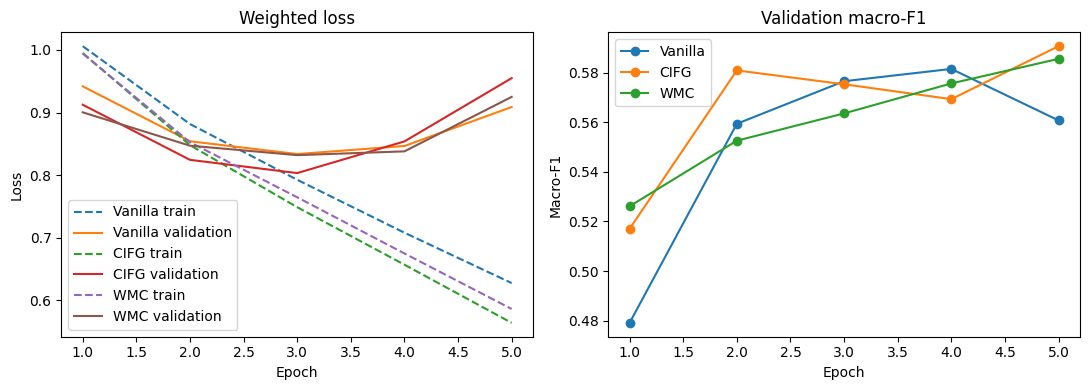

In [32]:
comparison_rows = []
for name in models:
    best = histories[name].loc[histories[name]['val_macro_f1'].idxmax()]
    comparison_rows.append({
        'Modèle': name,
        'Paramètres': sum(p.numel() for p in models[name].parameters() if p.requires_grad),
        'Meilleure époque': int(best['epoch']),
        'Accuracy validation': best['val_accuracy'],
        'Macro-F1 validation': best['val_macro_f1']
    })
comparison = pd.DataFrame(comparison_rows)
comparison.to_csv(WORK_DIR / 'comparaison_validation.csv', index=False)
display(comparison)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for name, frame in histories.items():
    axes[0].plot(frame['epoch'], frame['train_loss'], '--', label=name+' train')
    axes[0].plot(frame['epoch'], frame['val_loss'], label=name+' validation')
    axes[1].plot(frame['epoch'], frame['val_macro_f1'], marker='o', label=name)
axes[0].set(title='Weighted loss', xlabel='Epoch', ylabel='Loss')
axes[1].set(title='Validation macro-F1', xlabel='Epoch', ylabel='Macro-F1')
for ax in axes:
    ax.legend()
fig.tight_layout()
fig.savefig(WORK_DIR / 'learning_curves.png', dpi=180)
plt.show()


In [33]:
RUN_HYPERPARAMETERS = True

## 12. Étude des hyperparamètres — facultative à cette étape
Après avoir vérifié les trois résultats, mets `RUN_HYPERPARAMETERS = True` dans la première cellule. Quatre expériences sur **Vanilla** comparent un réglage à la fois : référence Adam/0,001/64, taux 0,0003, RMSprop, puis lots de 128. La référence est automatiquement rechargée.
Le budget est fixé à 5 époques ; changer la taille des lots change le nombre de mises à jour. Cette étude utilise une seule graine et une seule architecture : ce sont des limites à signaler. Le test n'intervient pas dans le choix.


In [34]:
if RUN_HYPERPARAMETERS:
    settings = [
        ('vanilla_adam_lr001_bs64', 0.001, 'Adam', 64),
        ('vanilla_adam_lr0003_bs64', 0.0003, 'Adam', 64),
        ('vanilla_rmsprop_lr001_bs64', 0.001, 'RMSprop', 64),
        ('vanilla_adam_lr001_bs128', 0.001, 'Adam', 128)
    ]
    hp_models, hp_histories, hp_rows = {}, {}, []
    for name, lr, opt, batch in settings:
        hp_models[name], hp_histories[name] = fit_experiment(name, 'Vanilla', lr, opt, batch)
        frame = hp_histories[name]
        best = frame.loc[frame['val_macro_f1'].idxmax()]
        hp_rows.append(dict(experiment=name, lr=lr, optimizer=opt, batch_size=batch,
                            epoch=int(best['epoch']), val_accuracy=best['val_accuracy'],
                            val_macro_f1=best['val_macro_f1']))
        pd.DataFrame(hp_rows).to_csv(WORK_DIR / 'hyperparameters.csv', index=False)
    hp_comparison = pd.DataFrame(hp_rows)
    display(hp_comparison)
else:
    print('Expériences supplémentaires désactivées pour le moment.')


vanilla_adam_lr001_bs64 : 5/5 époques déjà sauvegardées.
vanilla_adam_lr0003_bs64 : 5/5 époques déjà sauvegardées.
vanilla_rmsprop_lr001_bs64 : 5/5 époques déjà sauvegardées.
vanilla_adam_lr001_bs128 : 5/5 époques déjà sauvegardées.


,experiment,lr,optimizer,batch_size,epoch,val_accuracy,val_macro_f1
0,vanilla_adam_lr001_bs64,0.0010,Adam,64,4,0.684522,0.581565
1,vanilla_adam_lr0003_bs64,0.0003,Adam,64,5,0.661574,0.565440
2,vanilla_rmsprop_lr001_bs64,0.0010,RMSprop,64,5,0.720379,0.587110
3,vanilla_adam_lr001_bs128,0.0010,Adam,128,4,0.707284,0.579428


In [35]:
RUN_HYPERPARAMETERS = True
RUN_FINAL_TEST = True

## 13. Test final — à activer seulement une fois les réglages fixés
Mets les deux options `RUN_HYPERPARAMETERS` et `RUN_FINAL_TEST` à `True` lorsque l'étude est terminée et que tu es prêt à figer les choix. Le code compare les trois références et le Vanilla réglé s'il diffère de la référence ; le modèle final est **sélectionné sur la validation**, avant d'afficher le test. N'ajuste plus les réglages selon ces scores de test.


In [36]:
if RUN_FINAL_TEST:
    if not RUN_HYPERPARAMETERS:
        raise ValueError('Termine et active l’étude des hyperparamètres avant le test final.')
    candidates = dict(models)
    best_hp = hp_comparison.loc[hp_comparison['val_macro_f1'].idxmax()]
    hp_name = best_hp['experiment']
    if hp_name != 'vanilla_adam_lr001_bs64':
        candidates['Vanilla tuned'] = hp_models[hp_name]
    validation_scores = dict(zip(comparison['Modèle'], comparison['Macro-F1 validation']))
    if 'Vanilla tuned' in candidates:
        validation_scores['Vanilla tuned'] = float(best_hp['val_macro_f1'])
    final_name = max(validation_scores, key=validation_scores.get)
    print('Modèle final choisi sur la validation :', final_name)
    test_rows = []
    for name, candidate in candidates.items():
        metrics = run_epoch(candidate, test_loader)
        test_rows.append(dict(model=name, **metrics))
    test_results = pd.DataFrame(test_rows)
    test_results.to_csv(WORK_DIR / 'test_results.csv', index=False)
    display(test_results)
    targets, predictions = [], []
    final_model = candidates[final_name]
    final_model.eval()
    with torch.no_grad():
        for x, lengths, y in tqdm(test_loader, desc='Rapport final'):
            predictions.extend(final_model(x.to(device), lengths.to(device)).argmax(1).cpu().tolist())
            targets.extend(y.tolist())
    report = classification_report(targets, predictions, labels=[0, 1, 2],
                                   target_names=['Negative', 'Neutral', 'Positive'],
                                   output_dict=True, zero_division=0)
    display(pd.DataFrame(report).T)
    pd.DataFrame(report).T.to_csv(WORK_DIR / 'classification_report.csv')
    matrix = confusion_matrix(targets, predictions, labels=[0, 1, 2])
    pd.DataFrame(matrix, index=['Negative','Neutral','Positive'],
                 columns=['Negative','Neutral','Positive']).to_csv(WORK_DIR / 'confusion_matrix.csv')
    pd.DataFrame({'label': targets, 'prediction': predictions}).to_csv(
        WORK_DIR / 'test_predictions.csv', index=False)
    (WORK_DIR / 'final_selection.json').write_text(
        json.dumps({'model': final_name, 'criterion': 'validation_macro_f1',
                    'validation_scores': validation_scores}, indent=2), encoding='utf-8')
else:
    print('Test final désactivé : nous le gardons pour après le choix des hyperparamètres.')


Modèle final choisi sur la validation : CIFG


Évaluation:   0%|          | 0/755 [00:00<?, ?it/s]

Évaluation:   0%|          | 0/755 [00:00<?, ?it/s]

Évaluation:   0%|          | 0/755 [00:00<?, ?it/s]

Évaluation:   0%|          | 0/755 [00:00<?, ?it/s]

,model,loss,accuracy,macro_f1
0,Vanilla,0.860110,0.683462,0.577124
1,CIFG,0.965149,0.715866,0.592254
2,WMC,0.933256,0.706771,0.585684
3,Vanilla tuned,0.905221,0.719699,0.587366


Rapport final:   0%|          | 0/755 [00:00<?, ?it/s]

,precision,recall,f1-score,support
Negative,0.656869,0.742786,0.697191,12095.000000
Neutral,0.193920,0.372404,0.255037,4334.000000
Positive,0.911977,0.752395,0.824536,31837.000000
accuracy,0.715866,0.715866,0.715866,0.715866
macro avg,0.587589,0.622529,0.592254,48266.000000
weighted avg,0.783573,0.715866,0.741487,48266.000000


## 14. Archive de sauvegarde — toujours disponible dans Drive


In [37]:
from google.colab import files
# L'archive est à l'extérieur du dossier parcouru : elle ne s'inclut pas elle-même.
backup_path = PROJECT_DIR / 'Sauvegarde_RNN_corrigee.zip'
with zipfile.ZipFile(backup_path, 'w', zipfile.ZIP_DEFLATED) as archive:
    for path in sorted(WORK_DIR.rglob('*')):
        if path.is_file() and not path.name.endswith('.tmp') and path.name != 'drugsCom_raw.zip':
            archive.write(path, arcname=str(path.relative_to(WORK_DIR)))
print('Sauvegarde prête dans Drive :', backup_path)
# Pour télécharger aussi le ZIP sur ton ordinateur, décommente la ligne suivante :
# files.download(str(backup_path))
print('Pense aussi à télécharger le notebook .ipynb : il contient le code.')


Sauvegarde prête dans Drive : /content/drive/MyDrive/Projet_RNN_Drug_Review/Sauvegarde_RNN_corrigee.zip
Pense aussi à télécharger le notebook .ipynb : il contient le code.


In [38]:
from google.colab import files
files.download(str(backup_path))

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>